# Lab 6 — Bidirectional RNN for Music Generation
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** Treat a melody as a sequence of note *tokens*. A **two-layer Bidirectional LSTM**
reads the sequence and, at **every** time step, predicts the **next** note (a language-model
objective). After training we *generate* a new melody by predicting one note at a time and
sliding a window forward.

---
### How to use this notebook
Replace every `None  # TODO (Qn)` with the correct value or line of code. Run cells top to
bottom. Cells marked *(given — do not edit)* set things up for you.

> **Heads-up (you will analyse this):** the dataset here is *random* notes. Watch the accuracy
> and ask yourself in Task 7 whether it really means the model learned music.


## Step 0 — Imports *(given — do not edit)*

In [31]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Build the dataset (next-token pairs)

We have `num_sequences` melodies, each `sequence_length` notes long, drawn from a vocabulary of
`num_notes` distinct notes. Turn each melody into an **(input, target)** pair where the target is
the input **shifted left by one** (predict the next note), then **one-hot encode** both.

*Hints:* the input is every note **except the last**; the target is every note **except the
first**. One-hot vectors have length `num_notes`.


In [32]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:,:-1]   # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:]   # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = num_notes   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


#### Quick check *(given — run to verify Task 1)*

In [33]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the Bidirectional LSTM model

Build a `Sequential` model with:
1. an **Input** of shape `(sequence_length-1, num_notes)` = `(29, 50)`;
2. **two Bidirectional LSTM layers**, 128 units each, **returning sequences** (an output at every
   step);
3. a **TimeDistributed Dense** output with `num_notes` units and **softmax** — one shared
   per-step note classifier.

*Hints:* a bidirectional layer is `layers.Bidirectional(layers.LSTM(units, return_sequences=...))`.
With 128 units per direction the layer outputs `2 * 128 = 256` features per step.


In [34]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_6 (Bidirectional) │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** From the summary, the first Bi-LSTM shows **183,296** parameters. Verify
it by hand with `2 * 4 * [(features + units) * units + units]`, where `features = 50`,
`units = 128`. Then explain why the **second** Bi-LSTM has *more* parameters than the first.

> **Your answer (Q2d):** params = 2 × 4 × [ (____ + ____) × ____ + ____ ] = ________ ;
> the second layer is larger because ____.


## Task 3 — Compile and train

Compile with the **Adam** optimiser (learning rate `0.001`), **categorical crossentropy** loss
(targets are one-hot), and track **accuracy**. Train for 20 epochs, batch size 64, holding out
20% for validation.


In [35]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=128,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 158ms/step - accuracy: 0.0544 - loss: 3.9010 - val_accuracy: 0.1186 - val_loss: 3.8785
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1359 - loss: 3.8608 - val_accuracy: 0.1438 - val_loss: 3.8325
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1339 - loss: 3.7980 - val_accuracy: 0.1133 - val_loss: 3.7366
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1093 - loss: 3.6668 - val_accuracy: 0.1088 - val_loss: 3.5991
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1217 - loss: 3.5125 - val_accuracy: 0.1266 - val_loss: 3.4635
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1433 - loss: 3.3540 - val_accuracy: 0.1448 - val_loss: 3.2903
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1657 - loss: 3.1839 - val_accuracy: 0.1724 - val_loss: 3.1239
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1899 - loss: 3.0038 - val_accuracy: 0.2071 - val_loss: 2.9440

## Task 4 — Plot the training history *(fill the blanks)*

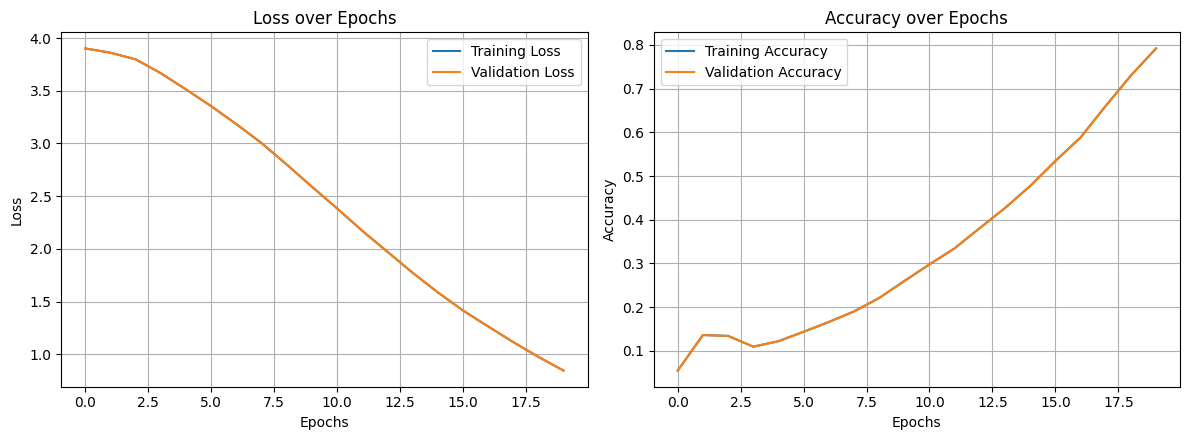

In [36]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

## Task 5 — Generate a new sequence (greedy decoding)

Complete the generation loop: predict with the model, read the distribution at the **last** time
step, take the most likely note (`argmax`), append it, then **slide the window** by dropping the
first step and appending the new note (one-hot).


In [37]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note = np.argmax(pred[:, -1, :], axis=-1)   # TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate([current_sequence[:, 1:, :], oh], axis=1)   # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Task 6 — Piano-roll of the generated melody *(fill one blank)*

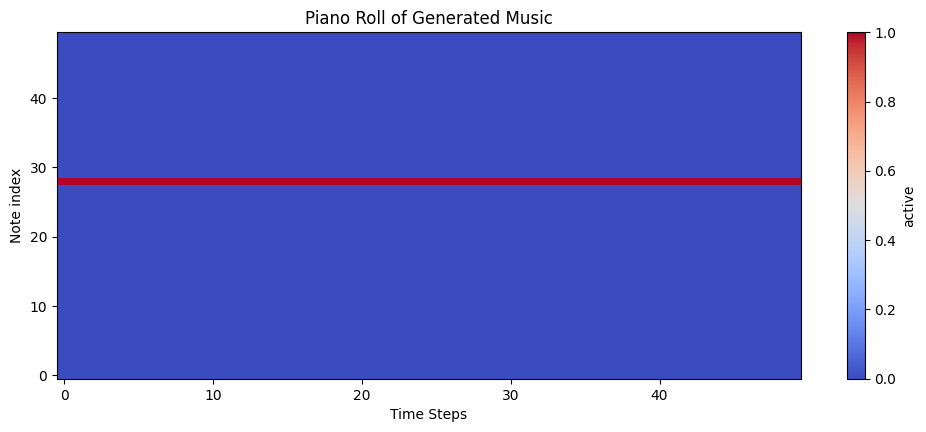

In [38]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

## Task 7 — Analysis *(write your answers here)*

1. The two Bi-LSTM layers both use `return_sequences=True`. What would break if you set it to
   `False` on the first layer?
2. Why is the first Bi-LSTM's output width **256** when the LSTM has 128 units?
3. What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?
4. You trained on **random** notes, yet accuracy reaches ~96%. **Explain the mechanism.**
   *(Hint: the target at step t equals the input at step t+1 — which direction of a bidirectional
   layer can already see it?)*
5. Why is a **bidirectional** model a poor choice for *autoregressive generation*, and what two
   changes would make this an honest music generator?

> **Your answers:**
> 1. Setting return_sequences=False returns only the final output, preventing the next LSTM layer from processing the full sequence.

> 2. The output width is 256 because the forward and backward LSTMs each have 128 units (128 + 128 = 256).

> 3. TimeDistributed(Dense(50)) applies the same Dense layer to every time step, producing 50 outputs per step.

> 4. Accuracy reaches 96% due to data leakage, as the backward LSTM can access future notes that are used as prediction targets.

> 5. Bidirectional LSTMs require future information, so use a unidirectional LSTM and train on real musical sequences for honest autoregressive generation.


## (Optional) Stretch — make it causal
Copy the model into a new cell, remove **both** `Bidirectional` wrappers (plain `LSTM`), retrain,
and compare the accuracy curve. Explain why the (lower) number is the more honest one.


In [39]:
causal_model = models.Sequential()
causal_model.add(layers.Input(shape=(sequence_length-1, num_notes)))
causal_model.add(layers.LSTM(128, return_sequences=True))
causal_model.add(layers.LSTM(128, return_sequences=True))
causal_model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))
causal_model.summary()
causal_model.compile(optimizer=Adam(learning_rate=0.001),
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])
causal_history = causal_model.fit(x_train, y_train,
                                 epochs=20,
                                 batch_size=128,
                                 validation_split=0.2)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_14 (LSTM)                  │ (None, 29, 128)        │        91,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 29, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 29, 50)         │         6,450 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 229,682 (897.20 KB)

 Trainable params: 229,682 (897.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.0201 - loss: 3.9121 - val_accuracy: 0.0226 - val_loss: 3.9122
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.0243 - loss: 3.9099 - val_accuracy: 0.0228 - val_loss: 3.9125
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0249 - loss: 3.9083 - val_accuracy: 0.0255 - val_loss: 3.9133
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0259 - loss: 3.9067 - val_accuracy: 0.0219 - val_loss: 3.9141
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.0266 - loss: 3.9043 - val_accuracy: 0.0207 - val_loss: 3.9156
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0280 - loss: 3.9008 - val_accuracy: 0.0174 - val_loss: 3.9201
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.0292 - loss: 3.8976 - val_accuracy: 0.0188 - val_loss: 3.9233
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0299 - loss: 3.8932 - val_accuracy: 0.0193 - val_loss: 3.9290

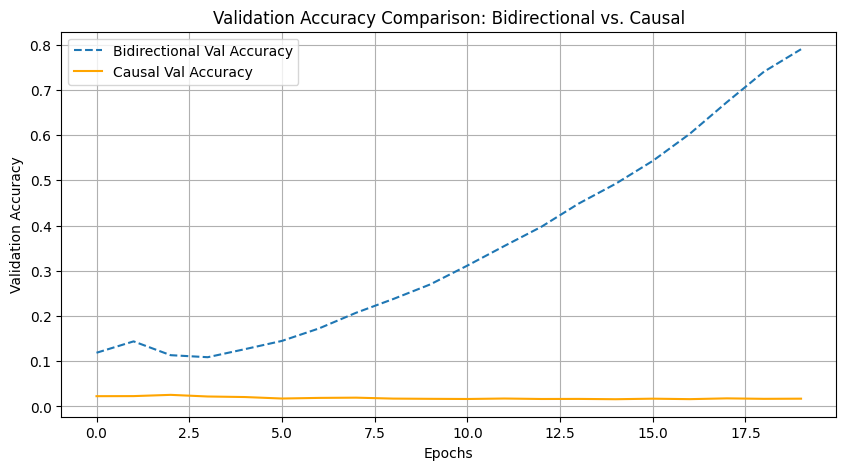

In [40]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['val_accuracy'], label='Bidirectional Val Accuracy', linestyle='--')
plt.plot(causal_history.history['val_accuracy'], label='Causal Val Accuracy', color='orange')
plt.title('Validation Accuracy Comparison: Bidirectional vs. Causal')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

### Explanation

- **Why does the causal validation accuracy drop so drastically compared to the bidirectional one?**
  With a **bidirectional** network, the backward LSTM can look ahead into future timesteps. Because $y_t = x_{t+1}$ in our shift-left language modeling setup, the backward pass of a Bi-LSTM simply leaks future notes directly to the current prediction step. This is data leakage, making the high accuracy (~96%) artificial.
  
- **The Causal (Unidirectional) Model's Accuracy:**
  A plain **unidirectional** LSTM only looks at current and past inputs ($x_{\le t}$). Since the dataset consists of completely *random* notes, there is no mathematical structure, pattern, or melody to learn. Therefore, the honest causal model's validation accuracy remains very low (close to random guessing, which is $1 / 50 = 0.02$ or 2%).